# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
os.makedirs('images', exist_ok=True)   # figures are saved here for the README

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('Aviation_Cleaned.csv', parse_dates=['Event.Date'])
print(df.shape)
df[['Make', 'Aircraft_Type', 'Total_Onboard', 'FatalSerious_Frac', 'Destroyed']].describe(include='all')

(56126, 31)


,Make,Aircraft_Type,Total_Onboard,FatalSerious_Frac,Destroyed
count,56126,56126,56126.000000,56126.000000,55325.000000
unique,45,1552,NaN,NaN,NaN
top,CESSNA,CESSNA 152,NaN,NaN,NaN
freq,24881,2213,NaN,NaN,NaN
mean,NaN,NaN,4.353793,0.274363,0.210917
std,NaN,NaN,20.854357,0.430475,0.407963
min,NaN,NaN,1.000000,0.000000,0.000000
25%,NaN,NaN,1.000000,0.000000,0.000000
50%,NaN,NaN,2.000000,0.000000,0.000000
75%,NaN,NaN,2.000000,0.683853,0.000000


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Split plane TYPES (Make+Model) into small / large using the passenger threshold of 20.
# A type is "large" if at least 25% of its accidents had >= 20 people on board (75th percentile).
# Using a type-level percentile (instead of per-event counts) avoids labelling a 737 with 5 people on a
# ferry flight as "small", while a Cessna in a mid-air collision with 30 people is not labelled "large".
type_q75 = df.groupby('Aircraft_Type')['Total_Onboard'].quantile(0.75)
large_types = type_q75[type_q75 >= 20].index
df['Size'] = np.where(df['Aircraft_Type'].isin(large_types), 'large', 'small')

print(df['Size'].value_counts())
print(df.groupby('Size')['Total_Onboard'].describe())

small = df[df['Size'] == 'small']
large = df[df['Size'] == 'large']

# Minimum samples per make so that averages are meaningful
MIN_SMALL, MIN_LARGE = 30, 10

def make_stats(d, min_n):
    g = d.groupby('Make').agg(n=('FatalSerious_Frac', 'size'),
                              mean_frac=('FatalSerious_Frac', 'mean'),
                              median_frac=('FatalSerious_Frac', 'median'),
                              std_frac=('FatalSerious_Frac', 'std'))
    return g[g['n'] >= min_n].sort_values('mean_frac')

small_makes = make_stats(small, MIN_SMALL)
large_makes = make_stats(large, MIN_LARGE)
print("\nmakes kept - small:", len(small_makes), "| large:", len(large_makes))

Size
small    55041
large     1085
Name: count, dtype: int64
         count        mean        std  min   25%    50%    75%    max
Size                                                                 
large   1085.0  121.273733  90.967695  1.0  53.0  113.0  166.0  576.0
small  55041.0    2.049000   2.389030  1.0   1.0    2.0    2.0  267.0

makes kept - small: 43 | large: 6


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

,n,mean_frac,median_frac,std_frac
Make,,,,
WACO,103,0.125,0.0,0.318
GREAT LAKES,57,0.149,0.0,0.353
MAULE,534,0.153,0.0,0.342
SCHWEIZER,167,0.153,0.0,0.359
BOEING STEARMAN,341,0.163,0.0,0.345
HELIO,73,0.170,0.0,0.363
STINSON,405,0.201,0.0,0.375
WEATHERLY,79,0.203,0.0,0.404
GRUMMAN,1423,0.204,0.0,0.394


,n,mean_frac,median_frac,std_frac
Make,,,,
EMBRAER,77,0.062,0.0,0.199
MCDONNELL DOUGLAS,159,0.069,0.0,0.220
BOMBARDIER,61,0.076,0.0,0.233
BOEING,620,0.127,0.0,0.312
AIRBUS,126,0.137,0.0,0.329
DE HAVILLAND,38,0.244,0.0,0.398


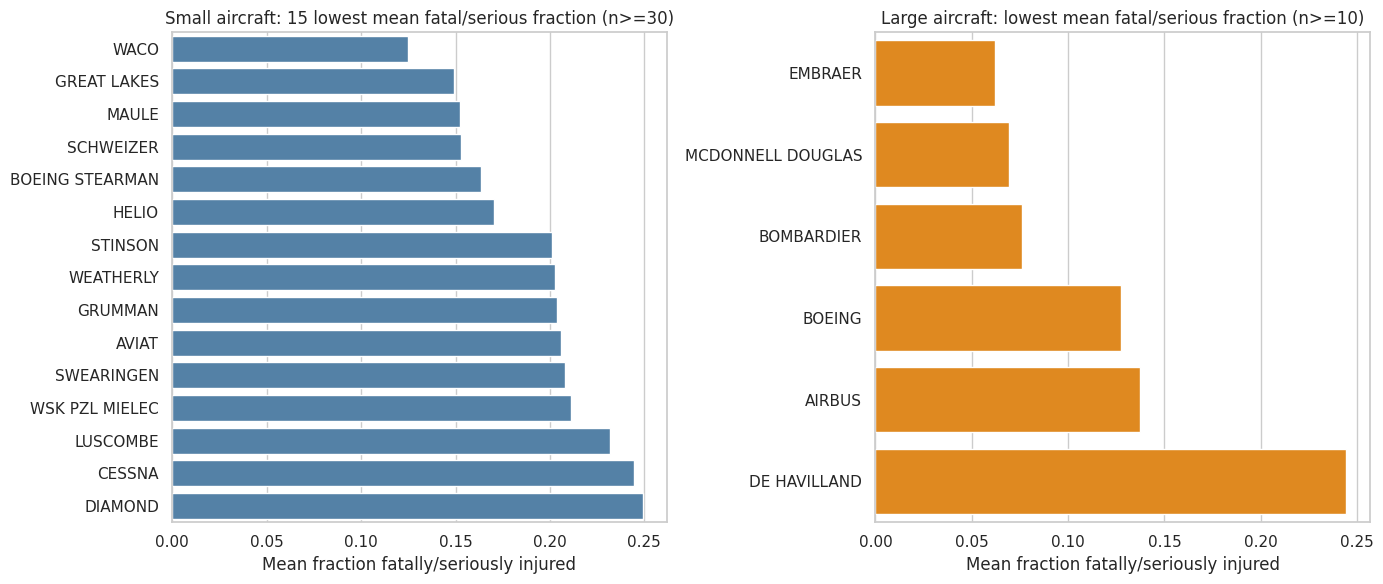

In [4]:
small_top15 = small_makes.head(15)
large_top15 = large_makes.head(15)     # fewer than 15 large makes have enough accidents
display(small_top15.round(3)); display(large_top15.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_top15['mean_frac'], y=small_top15.index, ax=axes[0], color='steelblue')
axes[0].set_title(f'Small aircraft: 15 lowest mean fatal/serious fraction (n>={MIN_SMALL})')
sns.barplot(x=large_top15['mean_frac'], y=large_top15.index, ax=axes[1], color='darkorange')
axes[1].set_title(f'Large aircraft: lowest mean fatal/serious fraction (n>={MIN_LARGE})')
for ax in axes:
    ax.set_xlabel('Mean fraction fatally/seriously injured'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/makes_mean_injury_fraction.png', dpi=150, bbox_inches='tight')
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

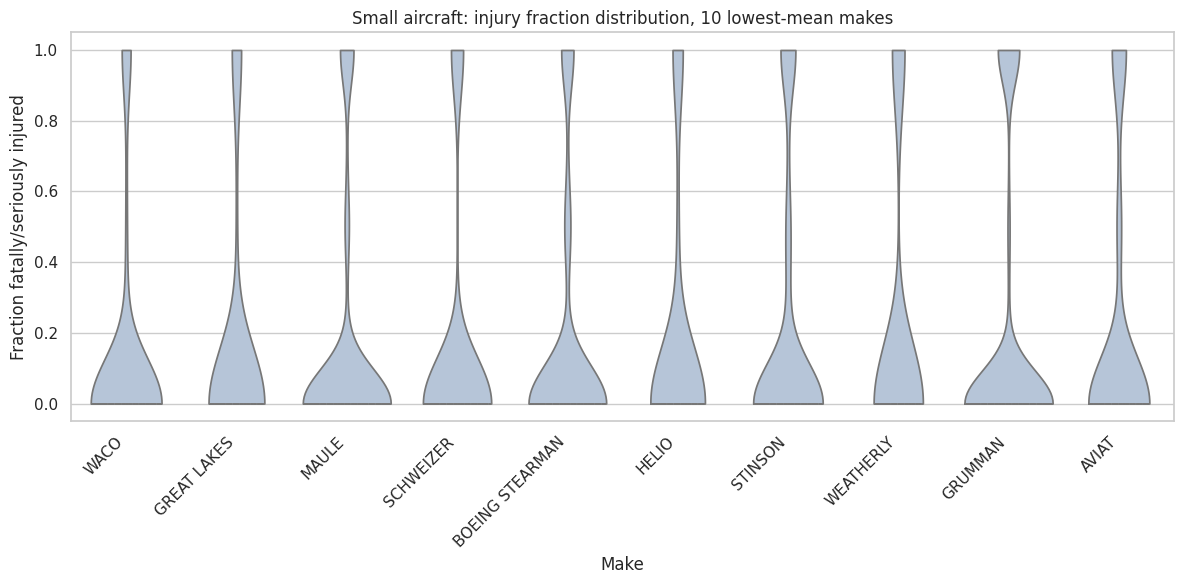

In [5]:
top10_small = small_makes.head(10).index
plt.figure(figsize=(12, 6))
sns.violinplot(data=small[small['Make'].isin(top10_small)], x='Make', y='FatalSerious_Frac',
               order=top10_small, cut=0, inner='quartile', color='lightsteelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Fraction fatally/seriously injured')
plt.title('Small aircraft: injury fraction distribution, 10 lowest-mean makes')
plt.tight_layout()
plt.savefig('images/small_makes_violin.png', dpi=150, bbox_inches='tight')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

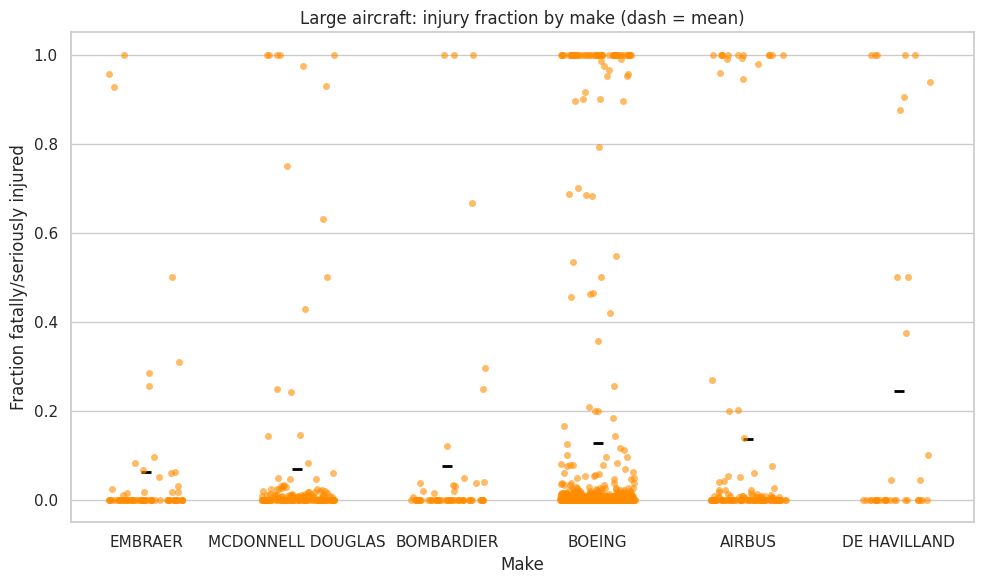

In [6]:
top10_large = large_makes.head(10).index
plt.figure(figsize=(10, 6))
sns.stripplot(data=large[large['Make'].isin(top10_large)], x='Make', y='FatalSerious_Frac',
              order=top10_large, jitter=0.25, alpha=0.6, color='darkorange')
sns.pointplot(data=large[large['Make'].isin(top10_large)], x='Make', y='FatalSerious_Frac',
              order=top10_large, linestyle='none', color='black', markers='_', errorbar=None)
plt.ylabel('Fraction fatally/seriously injured')
plt.title('Large aircraft: injury fraction by make (dash = mean)')
plt.tight_layout()
plt.savefig('images/large_makes_strip.png', dpi=150, bbox_inches='tight')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

,n,destroyed_frac
Make,,
DIAMOND,122,0.057
AVIAT,225,0.067
MAULE,533,0.086
BOEING STEARMAN,338,0.092
WACO,103,0.097
LUSCOMBE,367,0.101
TAYLORCRAFT,329,0.119
GREAT LAKES,57,0.123
STINSON,405,0.128


,n,destroyed_frac
Make,,
EMBRAER,40,0.075
BOMBARDIER,47,0.085
MCDONNELL DOUGLAS,119,0.134
BOEING,340,0.218
AIRBUS,62,0.290
DE HAVILLAND,34,0.294


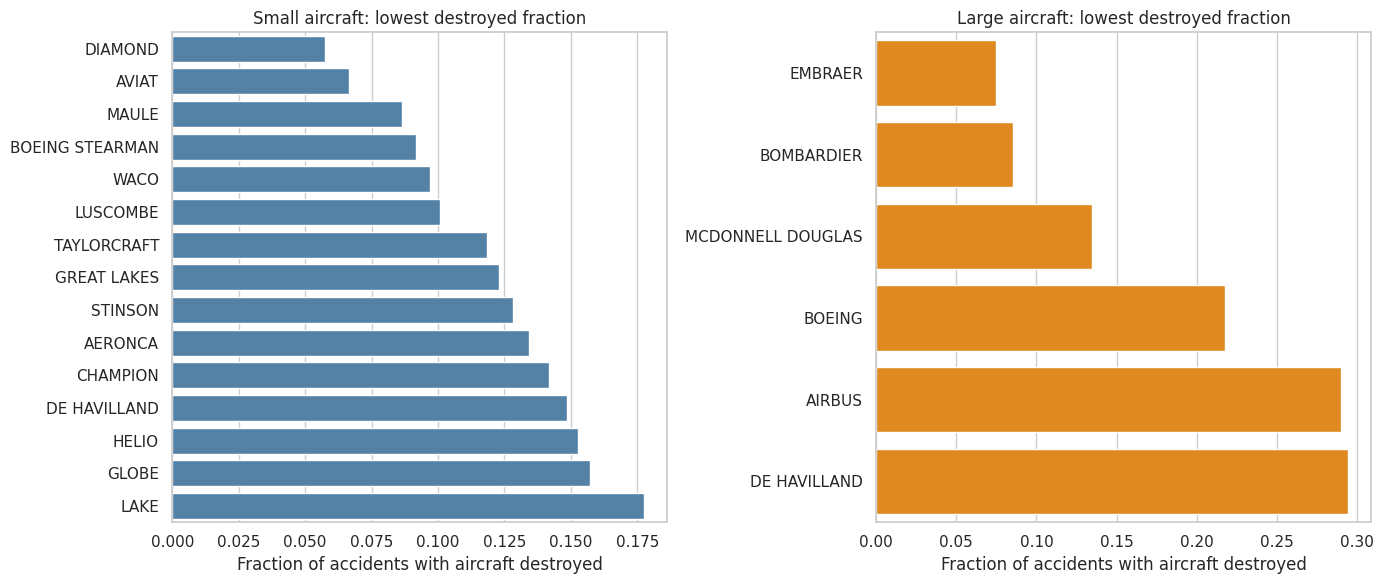

Small makes - combined view


,n,mean_frac,destroyed_frac
Make,,,
WACO,103,0.125,0.097
GREAT LAKES,57,0.149,0.123
MAULE,534,0.153,0.086
SCHWEIZER,167,0.153,0.204
BOEING STEARMAN,341,0.163,0.092
HELIO,73,0.170,0.153
STINSON,405,0.201,0.128
WEATHERLY,79,0.203,0.215
GRUMMAN,1423,0.204,0.237


Large makes - combined view


,n,mean_frac,destroyed_frac
Make,,,
EMBRAER,77,0.062,0.075
MCDONNELL DOUGLAS,159,0.069,0.134
BOMBARDIER,61,0.076,0.085
BOEING,620,0.127,0.218
AIRBUS,126,0.137,0.290
DE HAVILLAND,38,0.244,0.294


In [7]:
def destroyed_by_make(d, min_n):
    d = d.dropna(subset=['Destroyed'])
    g = d.groupby('Make').agg(n=('Destroyed', 'size'), destroyed_frac=('Destroyed', 'mean'))
    return g[g['n'] >= min_n].sort_values('destroyed_frac').head(15)

small_destroyed = destroyed_by_make(small, MIN_SMALL)
large_destroyed = destroyed_by_make(large, MIN_LARGE)
display(small_destroyed.round(3)); display(large_destroyed.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_destroyed['destroyed_frac'], y=small_destroyed.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small aircraft: lowest destroyed fraction')
sns.barplot(x=large_destroyed['destroyed_frac'], y=large_destroyed.index, ax=axes[1], color='darkorange')
axes[1].set_title('Large aircraft: lowest destroyed fraction')
for ax in axes:
    ax.set_xlabel('Fraction of accidents with aircraft destroyed'); ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/makes_destroyed_fraction.png', dpi=150, bbox_inches='tight')
plt.show()

# Combine both safety measures for a shortlist
both_small = small_makes.join(small.dropna(subset=['Destroyed']).groupby('Make')['Destroyed'].mean().rename('destroyed_frac'), how='inner')
both_large = large_makes.join(large.dropna(subset=['Destroyed']).groupby('Make')['Destroyed'].mean().rename('destroyed_frac'), how='inner')
print("Small makes - combined view"); display(both_small[['n', 'mean_frac', 'destroyed_frac']].round(3).head(10))
print("Large makes - combined view"); display(both_large[['n', 'mean_frac', 'destroyed_frac']].round(3))

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Discussion: makes (injury fraction and destruction rate)

**Method / robustness.** Plane types are split into small and large using the 20-people-on-board threshold (large = 75th percentile of people on board >= 20). Only makes with >= 30 accidents (small) or >= 10 accidents (large) are ranked, so a make is not ranked on a handful of events. Only 6 large makes meet the threshold, so the large-aircraft "top 15" is simply all of them.

**Small aircraft.**
- Lowest mean fatal/serious fraction: **Waco (0.125, n=103), Great Lakes (0.149, n=57), Maule (0.153, n=534), Schweizer (0.153, n=167), Boeing-Stearman (0.163, n=341)**. For comparison Cessna, by far the biggest make (n=24,881), is at 0.245.
- Lowest destroyed fraction: **Diamond (0.057), Aviat (0.067), Maule (0.086), Boeing-Stearman (0.091), Waco (0.097)**.
- **Maule is the only small make in the top five of both lists and has a large sample (n>500), so it is the most robust small-aircraft recommendation.** Aviat and Diamond (modern, strong airframes) have the lowest destruction rates and mid-range injury fractions (0.21 and 0.25).
- Distributions (violin plot): every make's median is 0 (most accidents injure nobody seriously), with a second mass at 1.0 (everyone on board). Means therefore reflect *how often* an accident is a "total loss of the occupants", and the make-to-make gaps (~0.13-0.20) are small relative to the within-make spread (std ~0.32-0.40). Differences among the top ~8 makes should not be over-interpreted; the difference between them and the overall small-aircraft mean (~0.25) is more meaningful where n is large (Maule, Boeing-Stearman).
- Caveat: Waco, Great Lakes and Boeing-Stearman are vintage biplanes flown mostly in low-speed, low-altitude, recreational/agricultural settings, so part of their good record reflects how they are used.

**Large aircraft.**
- Lowest mean fatal/serious fraction: **Embraer (0.062, n=77), McDonnell Douglas (0.069, n=159), Bombardier (0.076, n=61)**, followed by Boeing (0.127, n=620) and Airbus (0.137, n=126). De Havilland (0.244, n=38) is clearly worst (commuter Twin Otter-class turboprops).
- Lowest destroyed fraction: **Embraer (0.075), Bombardier (0.085), McDonnell Douglas (0.134)**; Boeing (0.218) and Airbus (0.290) are higher.
- In the strip plot almost all points sit at 0 with a small number at 1.0: a rare catastrophic crash drives the make average, so large-make means are noisy (n=61-159 for the top three). **Embraer, Bombardier and McDonnell Douglas are the recommended large makes**; Boeing and Airbus are acceptable but their averages are pulled up by a few high-fatality accidents.
- Caveat: accident data has no exposure term (flights flown). Makes with a huge fleet (Boeing) have more accidents, but the rates here are per accident, not per flight.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,n,mean_frac,destroyed_frac
Aircraft_Type,,,
BOEING 717200,11,0.002,0.000
BOEING 757223,11,0.004,0.000
MCDONNELL DOUGLAS MD88,23,0.005,0.000
BOEING 757232,17,0.005,0.000
AIRBUS A320232,12,0.006,0.000
BOEING 757222,11,0.007,0.000
EMBRAER ERJ170200LR,10,0.008,0.000
MCDONNELL DOUGLAS MD80,11,0.010,0.000
BOMBARDIER CL6002C10,16,0.027,0.000


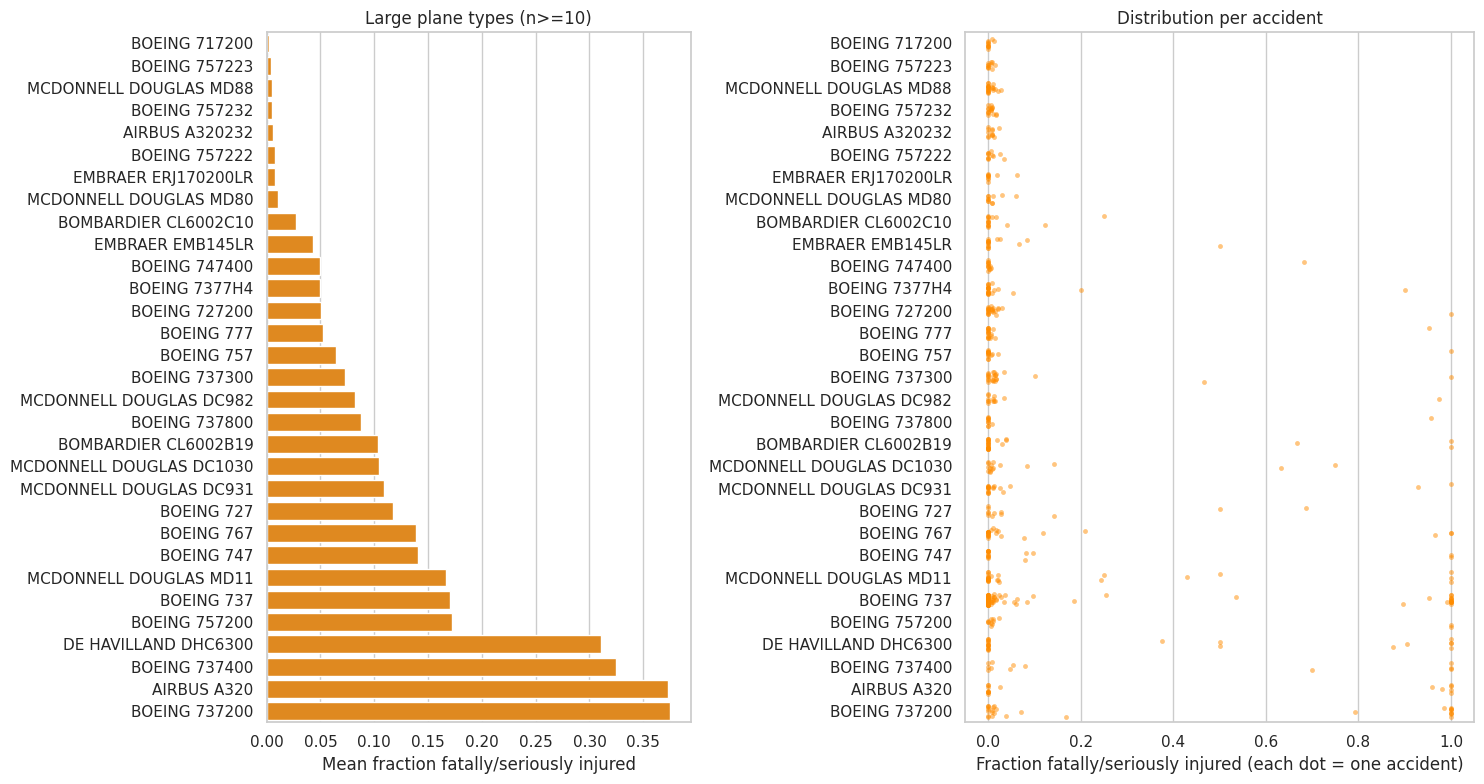

In [8]:
MIN_TYPE = 10
large_types_stats = (large.groupby('Aircraft_Type')
                     .agg(n=('FatalSerious_Frac', 'size'), mean_frac=('FatalSerious_Frac', 'mean'),
                          destroyed_frac=('Destroyed', 'mean'))
                     .query('n >= @MIN_TYPE').sort_values('mean_frac'))
display(large_types_stats.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [1, 1.2]})
sns.barplot(x=large_types_stats['mean_frac'], y=large_types_stats.index, ax=axes[0], color='darkorange')
axes[0].set_xlabel('Mean fraction fatally/seriously injured'); axes[0].set_ylabel('')
axes[0].set_title(f'Large plane types (n>={MIN_TYPE})')

order = large_types_stats.index
sns.stripplot(data=large[large['Aircraft_Type'].isin(order)], x='FatalSerious_Frac', y='Aircraft_Type',
              order=order, jitter=0.25, alpha=0.5, size=3.5, ax=axes[1], color='darkorange')
axes[1].set_xlabel('Fraction fatally/seriously injured (each dot = one accident)'); axes[1].set_ylabel('')
axes[1].set_title('Distribution per accident')
plt.tight_layout()
plt.savefig('images/large_types.png', dpi=150, bbox_inches='tight')
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

small types with >=10 accidents: 653


,n,mean_frac,destroyed_frac
Aircraft_Type,,,
CESSNA 180C,14,0.000,0.071
MCDONNELL DOUGLAS MD11F,10,0.000,0.111
BOEING STEARMAN D75N1,10,0.000,0.100
MAULE MX7235,24,0.021,0.042
MAULE M4,26,0.038,0.038
NORTH AMERICAN AT6G,12,0.042,0.000
CESSNA L19,11,0.045,0.091
PIPER PA18160,33,0.045,0.030
AYRES S2R600,20,0.050,0.200


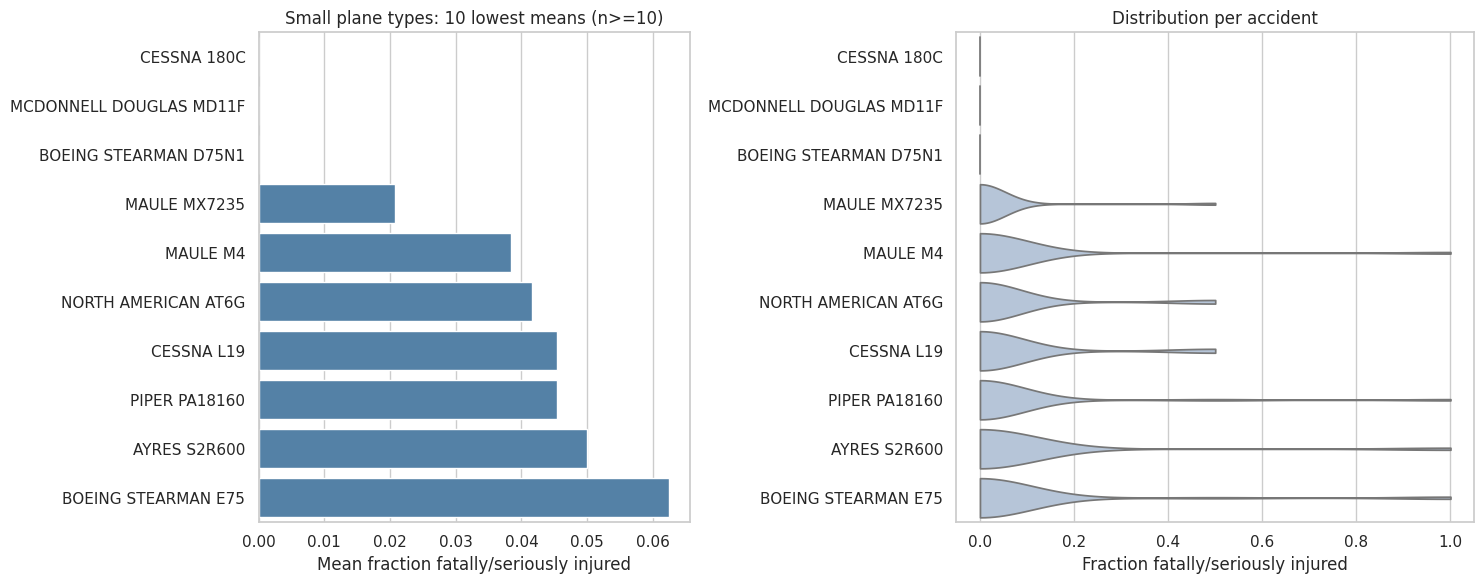

In [9]:
small_types_stats = (small.groupby('Aircraft_Type')
                     .agg(n=('FatalSerious_Frac', 'size'), mean_frac=('FatalSerious_Frac', 'mean'),
                          destroyed_frac=('Destroyed', 'mean'))
                     .query('n >= @MIN_TYPE').sort_values('mean_frac'))
print("small types with >=10 accidents:", len(small_types_stats))
small_types10 = small_types_stats.head(10)
display(small_types10.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.2]})
sns.barplot(x=small_types10['mean_frac'], y=small_types10.index, ax=axes[0], color='steelblue')
axes[0].set_xlabel('Mean fraction fatally/seriously injured'); axes[0].set_ylabel('')
axes[0].set_title('Small plane types: 10 lowest means (n>=10)')
sns.violinplot(data=small[small['Aircraft_Type'].isin(small_types10.index)], x='FatalSerious_Frac',
               y='Aircraft_Type', order=small_types10.index, cut=0, inner='stick', ax=axes[1],
               color='lightsteelblue', density_norm='width')
axes[1].set_xlabel('Fraction fatally/seriously injured'); axes[1].set_ylabel('')
axes[1].set_title('Distribution per accident')
plt.tight_layout()
plt.savefig('images/small_types.png', dpi=150, bbox_inches='tight')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Discussion: specific plane types (n >= 10 accidents per type)

**Large aircraft (31 types qualify).**
- Lowest injury fractions with zero destroyed aircraft: **Boeing 717-200 (0.002, n=11), Boeing 757-223 (0.004, n=11), McDonnell Douglas MD-88 (0.005, n=23), Boeing 757-232 (0.005, n=17), Airbus A320-232 (0.006, n=12), Boeing 757-222 (0.007, n=11), Embraer ERJ-170-200 (0.008, n=10), MD-80 (0.010, n=11), Bombardier CL-600-2C10 (0.027, n=16), Embraer EMB-145LR (0.043, n=16)**.
- Strong second tier with larger samples: Boeing 737-7H4 (0.050, n=24), Boeing 727-200 (0.050, n=23), Boeing 777 (0.052, n=19).
- Worst types: Boeing 737-200 (0.375, n=27, 58% destroyed), Airbus A320 (unspecified variant, 0.373, n=16), Boeing 737-400 (0.324, n=12), DHC-6-300 (0.311, n=23). The 737-200 is an old design (1960s) and should be avoided on insurance terms.
- The distribution plot shows for most large types the vast majority of accidents have ~0 fatal/serious fraction, and a couple of dots at/near 1.0 account for the averages of the poorer types.
- Sample-size caution: types with n=10-12 have wide uncertainty; recommendations are strongest for MD-88 (n=23), 737-7H4 (n=24), 727-200 (n=23), and 757 variants (n=11-17, consistent across three variants).

**Small aircraft (653 types with >= 10 accidents; 10 lowest shown).**
- Lowest: Cessna 180C (0.000, n=14), Boeing-Stearman D75N1 (0.000, n=10), **Maule MX-7-235 (0.021, n=24), Maule M-4 (0.038, n=26), Piper PA-18-160 Super Cub (0.045, n=33)**, North American AT-6G (0.042, n=12), Cessna L-19 (0.045, n=11), Ayres S2R-600 (0.050, n=20), Boeing-Stearman E75 (0.062, n=40).
- Maule and Piper Super Cub models are consistent with the make-level result and have the larger samples, so they are the most defensible specific small-plane recommendations. The two types with mean 0.000 have only 10-14 accidents, which is a small-sample result and should not be taken as "never injures anyone"; many of these are single-pilot ag/utility airplanes where accidents are often survivable.
- MD-11F appears in this list only because freighter crews are small; it is not a passenger model.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [10]:
def ci95(s):
    s = s.dropna(); n = len(s)
    return 1.96 * s.std() / np.sqrt(n) if n > 1 else np.nan

def factor_table(d, col, min_n=30):
    t = d.groupby(col).agg(n=('FatalSerious_Frac', 'size'),
                           mean_frac=('FatalSerious_Frac', 'mean'),
                           ci_frac=('FatalSerious_Frac', ci95),
                           destroyed_frac=('Destroyed', 'mean'))
    return t[t['n'] >= min_n].sort_values('mean_frac')

def factor_plot(d, col, order, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=d[d[col].isin(order)], x=col, y='FatalSerious_Frac', hue='Size', order=order,
                errorbar=('ci', 95), ax=axes[0], palette={'small': 'steelblue', 'large': 'darkorange'})
    axes[0].set_ylabel('Mean fraction fatally/seriously injured (95% CI)')
    sns.barplot(data=d[d[col].isin(order)].dropna(subset=['Destroyed']), x=col, y='Destroyed', hue='Size',
                order=order, errorbar=('ci', 95), ax=axes[1], palette={'small': 'steelblue', 'large': 'darkorange'})
    axes[1].set_ylabel('Fraction of accidents with aircraft destroyed (95% CI)')
    for ax in axes:
        ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f'images/{fname}.png', dpi=150, bbox_inches='tight')
    plt.show()

### Factor 1: Weather Condition (VMC vs IMC)

Weather.Condition
VMC    49355
IMC     4416
Name: count, dtype: int64 



,n,mean_frac,destroyed_frac
Weather.Condition,,,
IMC,4416,0.678,0.600
VMC,49355,0.224,0.167


n  mean_frac  destroyed_frac
Size  Weather.Condition                                  
large IMC                  164      0.185           0.323
      VMC                  591      0.051           0.074
small IMC                 4252      0.697           0.606
      VMC                48764      0.226           0.167

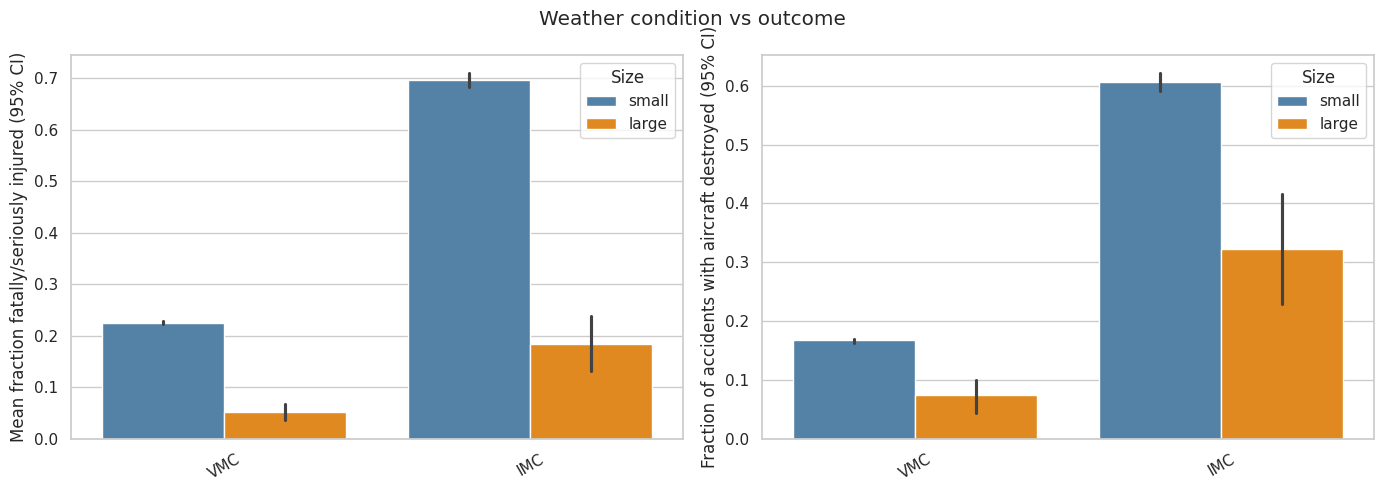

Mann-Whitney U (small, injury fraction): p = 0.0
Chi-square (small, destroyed): p = 0.0


In [11]:

wx = df[df['Weather.Condition'].isin(['VMC', 'IMC'])]      # 'Unknown' excluded
print(wx['Weather.Condition'].value_counts(), '\n')
display(wx.groupby('Weather.Condition').agg(n=('FatalSerious_Frac', 'size'), mean_frac=('FatalSerious_Frac', 'mean'),
                                           destroyed_frac=('Destroyed', 'mean')).round(3))
display(wx.groupby(['Size', 'Weather.Condition']).agg(n=('FatalSerious_Frac', 'size'), mean_frac=('FatalSerious_Frac', 'mean'),
                                                     destroyed_frac=('Destroyed', 'mean')).round(3))
factor_plot(wx, 'Weather.Condition', ['VMC', 'IMC'], 'Weather condition vs outcome', 'weather')

# Significance tests (small aircraft; large has too few IMC accidents)
v = small.loc[small['Weather.Condition'] == 'VMC', 'FatalSerious_Frac']
i = small.loc[small['Weather.Condition'] == 'IMC', 'FatalSerious_Frac']
print("Mann-Whitney U (small, injury fraction): p =", stats.mannwhitneyu(v, i).pvalue)
ct = pd.crosstab(wx.loc[wx['Size'] == 'small', 'Weather.Condition'], wx.loc[wx['Size'] == 'small', 'Destroyed'])
print("Chi-square (small, destroyed): p =", stats.chi2_contingency(ct)[1])


**Finding: instrument conditions (IMC) are strongly associated with worse outcomes.**
- Across all airplanes: VMC accidents (n=49,355) average a 0.224 fatal/serious fraction and 16.7% destroyed; IMC accidents (n=4,416) average **0.678 and 60.0% destroyed**, about 3x and 3.6x higher.
- The effect holds in both size classes: small aircraft 0.226 (VMC) vs 0.697 (IMC); large aircraft 0.051 (n=591) vs 0.185 (n=164), destroyed 7.4% vs 32.3%.
- Mann-Whitney U and chi-square tests (small aircraft, huge samples) give p ~ 0, so this is not noise; the 95% CIs in the plots do not overlap.
- Interpretation: IMC accidents are typically loss of control / controlled flight into terrain at speed, which are far less survivable than VMC landing accidents. For the client, an operator's share of IMC flying (and instrument rating/equipment) is a key risk factor to price. Note this is association, not proof of cause (IMC flights also differ in pilot/aircraft type).

### Factor 2: Broad Phase of Flight

,n,mean_frac,ci_frac,destroyed_frac
Broad.phase.of.flight,,,,
Taxi,1307,0.020,0.006,0.021
Landing,11084,0.035,0.003,0.042
Standing,530,0.155,0.024,0.133
Takeoff,8228,0.229,0.009,0.219
Go-around,1112,0.302,0.026,0.288
Descent,1201,0.342,0.026,0.338
Cruise,6688,0.352,0.011,0.346
Approach,4203,0.355,0.014,0.300
Climb,1275,0.438,0.026,0.444


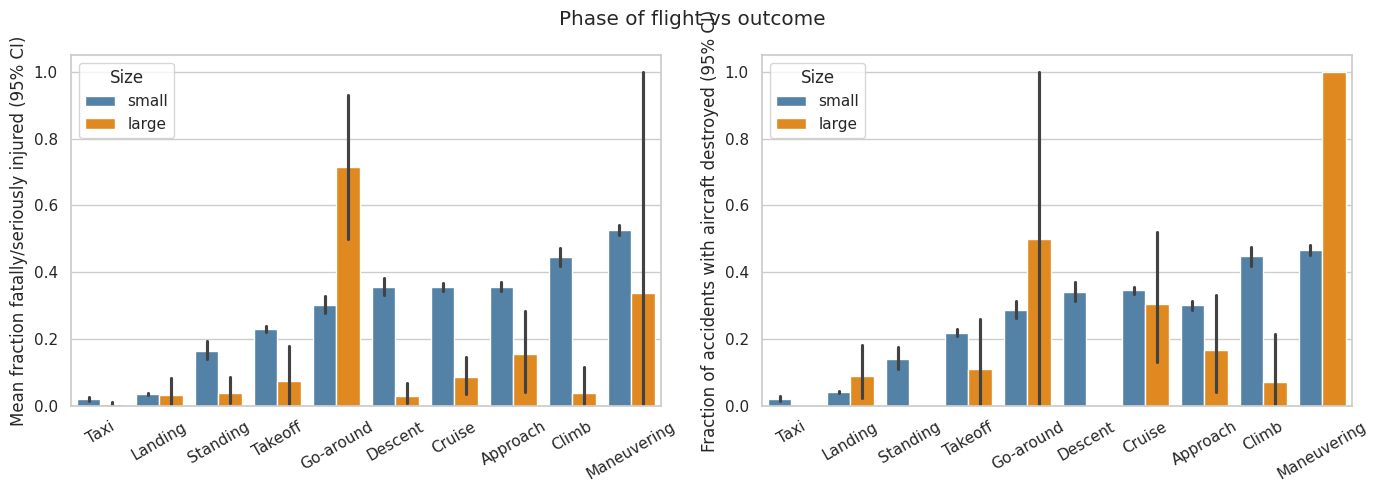

Kruskal-Wallis across phases: p = 0.0

Large aircraft only:


,n,mean_frac,ci_frac,destroyed_frac
Broad.phase.of.flight,,,,
Taxi,77,0.005,0.005,0.000
Descent,53,0.030,0.037,0.000
Landing,45,0.033,0.044,0.091
Climb,27,0.037,0.054,0.071
Standing,45,0.039,0.044,0.000
Takeoff,29,0.075,0.092,0.111
Cruise,83,0.087,0.055,0.304
Approach,29,0.154,0.125,0.167


In [12]:

ph = df[~df['Broad.phase.of.flight'].isin(['Unknown', 'Other'])]
ph_tab = factor_table(ph, 'Broad.phase.of.flight', min_n=100)
display(ph_tab.round(3))
phase_order = ph_tab.index.tolist()
factor_plot(ph, 'Broad.phase.of.flight', phase_order, 'Phase of flight vs outcome', 'phase')

groups = [g['FatalSerious_Frac'].values for _, g in ph[ph['Broad.phase.of.flight'].isin(phase_order)].groupby('Broad.phase.of.flight')]
print("Kruskal-Wallis across phases: p =", stats.kruskal(*groups).pvalue)
print("\nLarge aircraft only:")
display(factor_table(ph[ph['Size'] == 'large'], 'Broad.phase.of.flight', min_n=10).round(3))


**Finding: the phase of flight at the time of the accident matters a lot.**
- Safest phases: Taxi (0.020 fatal/serious fraction, 2.1% destroyed, n=1,307) and Landing (0.035, 4.2% destroyed, n=11,084).
- Most dangerous: **Maneuvering (0.527, 46.7% destroyed, n=4,346)** and Climb (0.438, 44.4% destroyed, n=1,275); Cruise, Approach and Descent sit at ~0.34-0.36. Takeoff is in the middle (0.229).
- A Kruskal-Wallis test across phases gives p ~ 0 and the 95% CIs separate the extremes clearly.
- Large aircraft only (table above, smaller samples so wide CIs): taxi 0.005 (n=77), descent 0.030, landing 0.033, climb 0.037; cruise (n=83) has the highest destroyed fraction at 30%. For large aircraft the data is too thin per phase to rank the middle phases reliably; only the taxi/landing vs cruise/approach contrast is solid.
- Interpretation: accidents that occur at low speed on the ground (taxi, landing roll) are survivable; accidents in the air with altitude/speed (maneuvering, climb, cruise) usually are not. Insurance exposure is therefore concentrated in operations with lots of maneuvering (e.g., aerial application, instruction, personal flying) rather than airline-style takeoff-cruise-land flying.

### Additional factor: Number of Engines

,n,mean_frac,ci_frac,destroyed_frac
Number.of.Engines,,,,
3,80,0.055,0.038,0.070
4,82,0.182,0.080,0.197
1,46903,0.252,0.004,0.187
2,6814,0.342,0.011,0.317


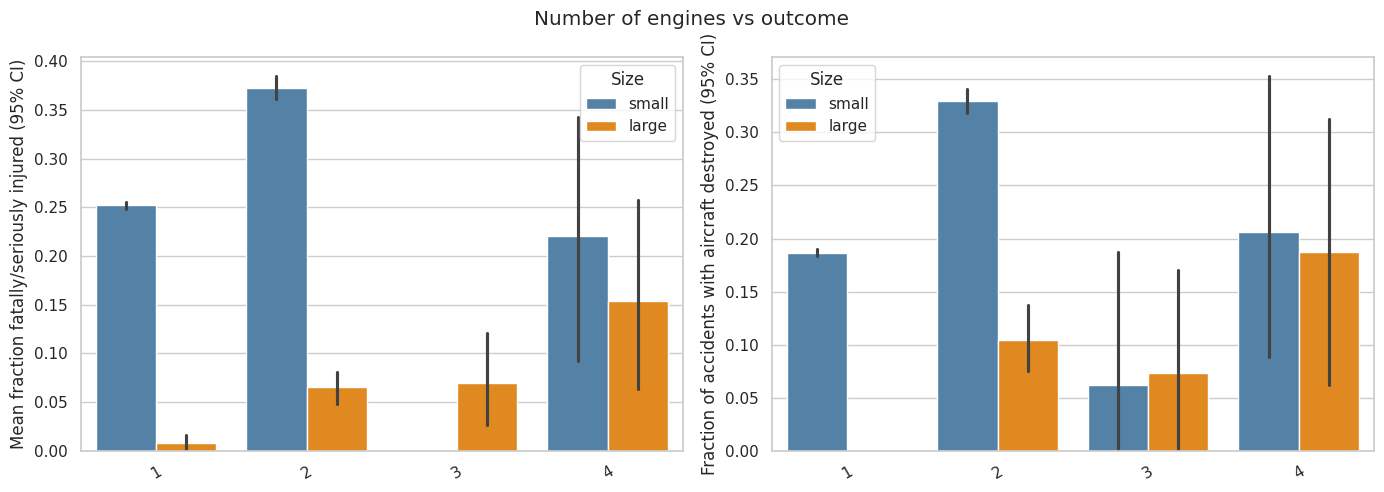


Small aircraft only:


,n,mean_frac,ci_frac,destroyed_frac
Number.of.Engines,,,,
4,35,0.221,0.127,0.206
1,46900,0.252,0.004,0.187
2,6125,0.373,0.012,0.330


In [13]:

ne = df.dropna(subset=['Number.of.Engines']).copy()
ne['Number.of.Engines'] = ne['Number.of.Engines'].astype(int).astype(str)
ne_tab = factor_table(ne, 'Number.of.Engines', min_n=30)
display(ne_tab.round(3))
factor_plot(ne, 'Number.of.Engines', ne_tab.sort_index().index.tolist(), 'Number of engines vs outcome', 'engines')
print("\nSmall aircraft only:"); display(factor_table(ne[ne['Size'] == 'small'], 'Number.of.Engines', 30).round(3))


**Finding: twin-engine aircraft have *higher* injury and destruction rates than single-engine aircraft in this data.**
- 1 engine: 0.252 fatal/serious fraction, 18.7% destroyed (n=46,903); **2 engines: 0.342 and 31.7% destroyed (n=6,814)**; for small airplanes only: 0.252 vs 0.373 (n=6,125).
- 3-engine (n=80, 0.055) and 4-engine (n=82, 0.182) groups are small and are mostly large aircraft, so they are not directly comparable to the 1-vs-2 contrast.
- The twin-vs-single gap is statistically clear given the sample sizes (non-overlapping 95% CIs) but is almost certainly confounded: twin-engine aircraft are faster, fly more often in IMC, at higher altitude, and carry more people than a typical single. More engines does not itself make an accident more dangerous; it flags the type of operation. Do not treat engine count as a causal safety lever.